# Activity Recognition — Classical Baseline

This notebook develops and evaluates a reproducible activity-recognition
baseline using the wearable-sensor dataset.

The initial model uses statistical features from five-second phone-accelerometer
windows. Model development uses fixed subject-wise cross-validation, while the
predefined test subjects remain reserved for final evaluation.

In [1]:
import pandas as pd

In [2]:
samples = pd.read_parquet("artifacts/samples.parquet")
train = samples[samples["split"].astype(str) == "train"]
test  = samples[samples["split"].astype(str) == "test"]

In [3]:
print("Train shape:", train.shape)
print("Reserved test shape:", test.shape)
display(train.head())

Train shape: (11921624, 11)
Reserved test shape: (3063648, 11)


,split,user_id,activity,device,sensor,window_id,window_idx,timestamp,x,y,z
0,train,1600,A,phone,accel,1600_phone_accel_A_0000,0,252207666810782,-0.364761,8.793503,1.055084
1,train,1600,A,phone,accel,1600_phone_accel_A_0000,1,252207717164786,-0.879730,9.768784,1.016998
2,train,1600,A,phone,accel,1600_phone_accel_A_0000,2,252207767518790,2.001495,11.109070,2.619156
3,train,1600,A,phone,accel,1600_phone_accel_A_0000,3,252207817872794,0.450623,12.651642,0.184555
4,train,1600,A,phone,accel,1600_phone_accel_A_0000,4,252207868226798,-2.164352,13.928436,-4.422485


## 1. Understand the training-data structure

The training table is stored in long format:

- one row represents one sensor measurement;
- `x`, `y`, and `z` are the three sensor axes;
- `timestamp` is the original nanosecond timestamp;
- `window_idx` is the sample position within a window;
- one `window_id` represents a five-second segment from one subject, activity,
  device, and sensor.

A window is currently sensor-specific. Phone accelerometer, phone gyroscope,
watch accelerometer, and watch gyroscope segments have different window IDs and
have not yet been combined into a multimodal example.

Only the training split will be used for data inspection and model-development
decisions. The test subjects should remain reserved for final evaluation.

In [4]:
ACTIVITY_MAP = {
    "A": "Walking",
    "B": "Jogging",
    "C": "Stairs",
    "D": "Sitting",
    "E": "Standing",
    "F": "Typing",
    "G": "Brushing Teeth",
    "H": "Eating Soup",
    "I": "Eating Chips",
    "J": "Eating Pasta",
    "K": "Drinking from Cup",
    "L": "Eating Sandwich",
    "M": "Kicking Soccer Ball",
    "O": "Playing Catch",
    "P": "Dribbling Basketball",
    "Q": "Writing",
    "R": "Clapping",
    "S": "Folding Clothes",
}

train_windows = (
    train.groupby("window_id", observed=True, sort=False)
    .agg(
        user_id=("user_id", "first"),
        activity=("activity", "first"),
        device=("device", "first"),
        sensor=("sensor", "first"),
        n_samples=("window_idx", "size"),
        start_timestamp=("timestamp", "min"),
        end_timestamp=("timestamp", "max"),
    )
    .reset_index()
)

train_windows["activity_code"] = train_windows["activity"].astype(str)
train_windows["activity_name"] = train_windows["activity_code"].map(ACTIVITY_MAP)
train_windows["observed_span_s"] = (
    train_windows["end_timestamp"] - train_windows["start_timestamp"]
) / 1e9

train_overview = pd.Series({
    "Sensor rows": len(train),
    "Windows": len(train_windows),
    "Subjects": train["user_id"].nunique(),
    "Activities": train["activity"].nunique(),
    "Devices": train["device"].nunique(),
    "Sensors": train["sensor"].nunique(),
})

display(train_overview.to_frame("value"))
display(
    train_windows[
        [
            "window_id",
            "user_id",
            "activity_name",
            "device",
            "sensor",
            "n_samples",
            "observed_span_s",
        ]
    ].head(10)
)

,value
Sensor rows,11921624
Windows,102729
Subjects,41
Activities,18
Devices,2
Sensors,2


,window_id,user_id,activity_name,device,sensor,n_samples,observed_span_s
0,1600_phone_accel_A_0000,1600,Walking,phone,accel,100,4.985046
1,1600_phone_accel_A_0001,1600,Walking,phone,accel,99,4.934703
2,1600_phone_accel_A_0002,1600,Walking,phone,accel,99,4.934692
3,1600_phone_accel_A_0003,1600,Walking,phone,accel,100,4.985038
4,1600_phone_accel_A_0004,1600,Walking,phone,accel,99,4.934692
5,1600_phone_accel_A_0005,1600,Walking,phone,accel,99,4.934708
6,1600_phone_accel_A_0006,1600,Walking,phone,accel,100,4.985046
7,1600_phone_accel_A_0007,1600,Walking,phone,accel,99,4.934686
8,1600_phone_accel_A_0008,1600,Walking,phone,accel,99,4.934692
9,1600_phone_accel_A_0009,1600,Walking,phone,accel,99,4.934681


### 1.1 Inspect one complete training window

Looking at a complete window is more informative than displaying unrelated rows
from the full table. The example below selects the first phone-accelerometer
Walking window, converts its timestamp to relative seconds, and displays its
metadata and first measurements.

In [5]:
example_window_id = train_windows.loc[
    (train_windows["activity_code"] == "A")
    & (train_windows["device"].astype(str) == "phone")
    & (train_windows["sensor"].astype(str) == "accel"),
    "window_id",
].iloc[0]

example = (
    train.loc[train["window_id"] == example_window_id]
    .sort_values("window_idx")
    .copy()
)

example["time_s"] = (
    example["timestamp"] - example["timestamp"].iloc[0]
) / 1e9

example_summary = pd.Series({
    "Window ID": example_window_id,
    "Subject": int(example["user_id"].iloc[0]),
    "Activity": ACTIVITY_MAP[str(example["activity"].iloc[0])],
    "Device": str(example["device"].iloc[0]),
    "Sensor": str(example["sensor"].iloc[0]),
    "Samples": len(example),
    "Observed span (s)": example["time_s"].iloc[-1],
})

display(example_summary.to_frame("value"))
display(
    example[
        ["window_idx", "time_s", "timestamp", "x", "y", "z"]
    ].head(10)
)

,value
Window ID,1600_phone_accel_A_0000
Subject,1600
Activity,Walking
Device,phone
Sensor,accel
Samples,100
Observed span (s),4.985046


,window_idx,time_s,timestamp,x,y,z
0,0,0.000000,252207666810782,-0.364761,8.793503,1.055084
1,1,0.050354,252207717164786,-0.879730,9.768784,1.016998
2,2,0.100708,252207767518790,2.001495,11.109070,2.619156
3,3,0.151062,252207817872794,0.450623,12.651642,0.184555
4,4,0.201416,252207868226798,-2.164352,13.928436,-4.422485
5,5,0.251770,252207918580802,-4.332779,13.361191,-0.718872
6,6,0.302124,252207968934806,-0.319443,13.318359,-0.232025
7,7,0.352478,252208019288809,1.566452,9.515274,-0.017776
8,8,0.402832,252208069642813,-0.323746,5.262665,0.322342
9,9,0.453186,252208119996817,-1.811676,3.710510,1.373932


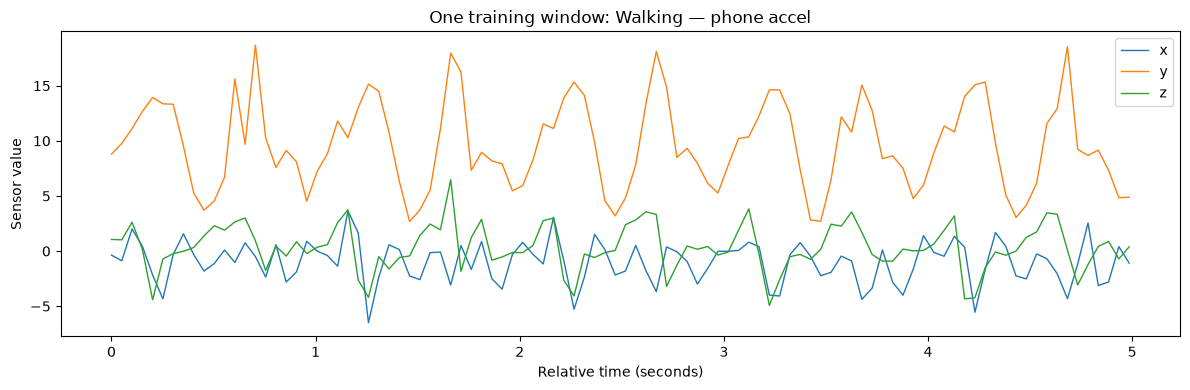

In [6]:
import matplotlib.pyplot as plt

ax = example.plot(
    x="time_s",
    y=["x", "y", "z"],
    figsize=(12, 4),
    linewidth=1,
)

ax.set(
    title=(
        f"One training window: "
        f"{ACTIVITY_MAP[str(example['activity'].iloc[0])]} — "
        f"{example['device'].iloc[0]} {example['sensor'].iloc[0]}"
    ),
    xlabel="Relative time (seconds)",
    ylabel="Sensor value",
)

plt.tight_layout()
plt.show()

## 2. Pre-model window checks

Before extracting features or training a model, we verify that each window has
one subject, activity, device, and sensor; that its sample positions are valid;
and that the train and test subjects are disjoint.

We also examine temporal coverage and internal timestamp gaps. The thresholds
below are diagnostic flags, not final filtering rules.

In [7]:
window_integrity = (
    train.groupby("window_id", observed=True, sort=False)
    .agg(
        n_users=("user_id", "nunique"),
        n_activities=("activity", "nunique"),
        n_devices=("device", "nunique"),
        n_sensors=("sensor", "nunique"),
        n_samples=("window_idx", "size"),
        n_unique_indices=("window_idx", "nunique"),
        min_index=("window_idx", "min"),
        max_index=("window_idx", "max"),
    )
)

bad_metadata = (
    (window_integrity["n_users"] != 1)
    | (window_integrity["n_activities"] != 1)
    | (window_integrity["n_devices"] != 1)
    | (window_integrity["n_sensors"] != 1)
)

bad_indices = (
    (window_integrity["min_index"] != 0)
    | (
        window_integrity["max_index"]
        != window_integrity["n_samples"] - 1
    )
    | (
        window_integrity["n_unique_indices"]
        != window_integrity["n_samples"]
    )
)

train_users = set(train["user_id"].unique())
test_users = set(test["user_id"].unique())

print("Windows with mixed metadata:", int(bad_metadata.sum()))
print("Windows with invalid sample indices:", int(bad_indices.sum()))
print("Subjects appearing in both splits:", sorted(train_users & test_users))

assert not bad_metadata.any()
assert not bad_indices.any()
assert train_users.isdisjoint(test_users)

Windows with mixed metadata: 0
Windows with invalid sample indices: 0
Subjects appearing in both splits: []


In [8]:
timestamp_step_s = (
    train.groupby("window_id", observed=True, sort=False)["timestamp"]
    .diff()
    .div(1e9)
)

max_gap_by_window = (
    timestamp_step_s
    .groupby(train["window_id"], observed=True, sort=False)
    .max()
    .rename("max_gap_s")
    .reset_index()
)

train_window_quality = train_windows.merge(
    max_gap_by_window,
    on="window_id",
    how="left",
    validate="one_to_one",
)

display(
    train_window_quality[
        ["n_samples", "observed_span_s", "max_gap_s"]
    ]
    .describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
    .T
)

print(
    "Windows with non-increasing timestamps:",
    int((timestamp_step_s <= 0).sum()),
)
print(
    "Windows with observed span below 4.5 seconds:",
    int((train_window_quality["observed_span_s"] < 4.5).sum()),
)
print(
    "Windows with an internal gap above 0.5 seconds:",
    int((train_window_quality["max_gap_s"] > 0.5).sum()),
)

,count,mean,std,min,1%,5%,50%,95%,99%,max
n_samples,102729.0,116.049256,43.141773,57.000000,99.000000,99.000000,100.000000,248.000000,249.000000,504.000000
observed_span_s,102729.0,4.954351,0.023599,2.796956,4.934169,4.934690,4.946236,4.992282,4.996831,4.999836
max_gap_s,102729.0,0.047452,0.016343,0.009951,0.020142,0.020341,0.049932,0.050361,0.050384,1.569808


Windows with non-increasing timestamps: 0
Windows with observed span below 4.5 seconds: 4
Windows with an internal gap above 0.5 seconds: 2


### 2.1 Training support at the window level

Because sampling frequencies differ, class support is measured using windows
and subjects rather than raw sensor-row counts. Device–sensor counts are shown
separately because each current window contains only one sensor stream.

In [9]:
activity_support = (
    train_windows
    .groupby(
        ["activity_code", "activity_name"],
        observed=True,
        sort=False,
    )
    .agg(
        windows=("window_id", "size"),
        subjects=("user_id", "nunique"),
    )
    .reset_index()
    .sort_values("windows")
)

stream_support = pd.crosstab(
    train_windows["activity_name"],
    [
        train_windows["device"].astype(str),
        train_windows["sensor"].astype(str),
    ],
)

display(activity_support)
display(stream_support)

,activity_code,activity_name,windows,subjects
5,F,Typing,5537,40
1,B,Jogging,5539,40
2,C,Stairs,5575,40
9,J,Eating Pasta,5676,41
11,L,Eating Sandwich,5714,41
13,O,Playing Catch,5715,41
7,H,Eating Soup,5715,41
15,Q,Writing,5747,41
16,R,Clapping,5748,41
14,P,Dribbling Basketball,5749,41


device               phone       watch      
sensor               accel  gyro accel  gyro
activity_name                               
Brushing Teeth        1446  1436  1435  1435
Clapping              1443  1435  1435  1435
Dribbling Basketball  1444  1435  1435  1435
Drinking from Cup     1444  1436  1436  1435
Eating Chips          1444  1435  1436  1435
Eating Pasta          1441  1435  1400  1400
Eating Sandwich       1444  1400  1435  1435
Eating Soup           1444  1435  1436  1400
Folding Clothes       1445  1435  1436  1435
Jogging               1373  1365  1401  1400
Kicking Soccer Ball   1443  1435  1438  1438
Playing Catch         1443  1435  1437  1400
Sitting               1445  1435  1438  1435
Stairs                1409  1400  1401  1365
Standing              1447  1435  1436  1435
Typing                1371  1365  1401  1400
Walking               1444  1435  1436  1435
Writing               1441  1435  1436  1435

### 2.2 Inspect the flagged windows

Only a very small number of training windows have unusually short observed
coverage or a large internal timestamp gap. We inspect their metadata before
deciding whether to exclude them.

The thresholds are based only on training data and will later be applied
unchanged to validation or test data.

In [10]:
flagged_windows = (
    train_window_quality
    .assign(
        short_span=lambda df: df["observed_span_s"] < 4.5,
        large_gap=lambda df: df["max_gap_s"] > 0.5,
    )
    .loc[lambda df: df["short_span"] | df["large_gap"]]
    .sort_values(["user_id", "activity_name", "device", "sensor"])
)

display(
    flagged_windows[
        [
            "window_id",
            "user_id",
            "activity_name",
            "device",
            "sensor",
            "n_samples",
            "observed_span_s",
            "max_gap_s",
            "short_span",
            "large_gap",
        ]
    ]
)

print("Unique flagged windows:", len(flagged_windows))

,window_id,user_id,activity_name,device,sensor,n_samples,observed_span_s,max_gap_s,short_span,large_gap
76320,1649_watch_accel_M_0022,1649,Kicking Soccer Ball,watch,accel,69,4.915882,1.569808,False,True
76322,1649_watch_accel_M_0052,1649,Kicking Soccer Ball,watch,accel,58,2.846902,0.049946,True,False
76323,1649_watch_accel_M_0057,1649,Kicking Soccer Ball,watch,accel,67,3.296468,0.049946,True,False
101908,1649_watch_gyro_M_0022,1649,Kicking Soccer Ball,watch,gyro,70,4.965822,1.569808,False,True
101910,1649_watch_gyro_M_0052,1649,Kicking Soccer Ball,watch,gyro,57,2.796956,0.049946,True,False
101911,1649_watch_gyro_M_0057,1649,Kicking Soccer Ball,watch,gyro,68,3.346415,0.049946,True,False


Unique flagged windows: 6


### 2.3 Pre-model findings

The training windows have consistent metadata and valid sample indices, and
there is no subject overlap between the predefined training and test splits.

Most windows provide nearly five seconds of continuous observations. Six
windows fail the preliminary temporal-quality criteria. They represent three
time positions from subject 1649 performing Kicking Soccer Ball, with the same
irregularities appearing in both watch accelerometer and watch gyroscope
streams. This is consistent with a watch-level recording interruption.

Windows will therefore be retained only when they have:

- at least 4.5 seconds of observed temporal coverage; and
- no internal timestamp gap greater than 0.5 seconds.

These rules were selected using training data and must be applied unchanged to
validation and test data. Subjects or complete recordings will not be removed
because of these isolated window-level problems.

Activity support is well balanced at the window level. Every activity is
represented by 40 or 41 training subjects, and total support ranges from 5,537
to 5,754 windows per activity. Class weighting is therefore not necessary for
the initial baseline, although macro-averaged metrics should still be reported.

The data is now ready for construction of a first window-level baseline.

## 3. Reproducible evaluation protocol

All model-development comparisons will use the same fixed subject-wise
cross-validation folds.

The 41 development subjects are divided into five reproducible validation
folds. Every window from a subject belongs to the same fold. The predefined
10 test subjects remain untouched until preprocessing, features, and model
choices have been finalized.

The primary model-selection metric is mean validation macro-F1. Additional
metrics are:

- standard deviation of macro-F1 across subject folds;
- balanced accuracy;
- overall accuracy;
- per-activity precision, recall, and F1;
- a row-normalized confusion matrix;
- performance across individual held-out subjects.

The same activity order, window-quality rules, and validation subjects will be
used for every directly comparable model.

In [11]:
import platform
import numpy as np
import sklearn

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.12.1
NumPy: 2.5.2
pandas: 3.0.5
scikit-learn: 1.9.0


### 3.1 Fixed subject-validation folds

In [12]:
from sklearn.model_selection import KFold

RANDOM_STATE = 42
N_FOLDS = 5

ACTIVITY_CODES = list(ACTIVITY_MAP)
ACTIVITY_NAMES = [ACTIVITY_MAP[code] for code in ACTIVITY_CODES]

development_subjects = np.array(
    sorted(train["user_id"].unique()),
    dtype=int,
)

subject_splitter = KFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

fold_records = []

for fold, (_, validation_positions) in enumerate(
    subject_splitter.split(development_subjects),
    start=1,
):
    for user_id in development_subjects[validation_positions]:
        fold_records.append({
            "user_id": int(user_id),
            "fold": fold,
        })

validation_folds = (
    pd.DataFrame(fold_records)
    .sort_values(["fold", "user_id"])
    .reset_index(drop=True)
)

FOLD_BY_SUBJECT = validation_folds.set_index("user_id")["fold"].to_dict()

fold_overview = (
    validation_folds
    .groupby("fold")
    .agg(
        n_subjects=("user_id", "size"),
        validation_subjects=("user_id", lambda values: tuple(values)),
    )
)

display(fold_overview)

assert validation_folds["user_id"].is_unique
assert set(validation_folds["user_id"]) == set(development_subjects)

,n_subjects,validation_subjects
fold,,
1,9,"(1604, 1610, 1615, 1622, 1628, 1630, 1634, 164..."
2,8,"(1608, 1611, 1614, 1617, 1619, 1620, 1631, 1637)"
3,8,"(1600, 1601, 1605, 1613, 1632, 1635, 1642, 1644)"
4,8,"(1602, 1603, 1624, 1627, 1636, 1638, 1645, 1647)"
5,8,"(1609, 1612, 1616, 1621, 1623, 1625, 1633, 1648)"


In [13]:
subject_activity_coverage = (
    train[["user_id", "activity"]]
    .drop_duplicates()
    .assign(
        activity_code=lambda df: df["activity"].astype(str),
        fold=lambda df: df["user_id"].map(FOLD_BY_SUBJECT),
    )
)

fold_activity_coverage = pd.crosstab(
    subject_activity_coverage["fold"],
    subject_activity_coverage["activity_code"],
).reindex(columns=ACTIVITY_CODES, fill_value=0)

display(
    fold_activity_coverage.rename(columns=ACTIVITY_MAP)
)

activities_per_fold = (fold_activity_coverage > 0).sum(axis=1)

print("Activities represented in each fold:")
display(activities_per_fold.to_frame("n_activities"))

assert activities_per_fold.eq(len(ACTIVITY_CODES)).all()

activity_code,Walking,Jogging,Stairs,Sitting,Standing,Typing,Brushing Teeth,Eating Soup,Eating Chips,Eating Pasta,Drinking from Cup,Eating Sandwich,Kicking Soccer Ball,Playing Catch,Dribbling Basketball,Writing,Clapping,Folding Clothes
fold,,,,,,,,,,,,,,,,,,
1,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
2,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8
3,8,8,7,8,8,7,8,8,8,8,8,8,8,8,8,8,8,8
4,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8
5,8,7,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8,8


Activities represented in each fold:


,n_activities
fold,
1,18
2,18
3,18
4,18
5,18


### 3.2 Reusable evaluation metrics

These functions operate on out-of-fold predictions from any model. These functions operate on out-of-fold predictions from any model, allowing all baselines and later models to be evaluated using the same protocol.

In [14]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    recall_score,
)


def calculate_metrics(y_true, y_pred, *, labels=ACTIVITY_CODES):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
    }


def summarize_oof_predictions(predictions):
    required_columns = {
        "window_id",
        "user_id",
        "fold",
        "y_true",
        "y_pred",
    }

    missing_columns = required_columns - set(predictions.columns)
    if missing_columns:
        raise ValueError(f"Missing prediction columns: {missing_columns}")

    fold_metrics = pd.DataFrame([
        {
            "fold": fold,
            **calculate_metrics(group["y_true"], group["y_pred"]),
        }
        for fold, group in predictions.groupby("fold", sort=True)
    ])

    fold_summary = (
        fold_metrics[
            ["accuracy", "balanced_accuracy", "macro_f1"]
        ]
        .agg(["mean", "std"])
        .T
    )

    overall_metrics = pd.Series(
        calculate_metrics(
            predictions["y_true"],
            predictions["y_pred"],
        ),
        name="all_oof_windows",
    )

    precision, recall, f1, support = precision_recall_fscore_support(
        predictions["y_true"],
        predictions["y_pred"],
        labels=ACTIVITY_CODES,
        zero_division=0,
    )

    per_activity = pd.DataFrame({
        "activity_code": ACTIVITY_CODES,
        "activity_name": ACTIVITY_NAMES,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
    })

    subject_rows = []

    for user_id, group in predictions.groupby("user_id", sort=True):
        labels_present = [
            code
            for code in ACTIVITY_CODES
            if code in set(group["y_true"])
        ]

        subject_rows.append({
            "user_id": user_id,
            "n_windows": len(group),
            **calculate_metrics(
                group["y_true"],
                group["y_pred"],
                labels=labels_present,
            ),
        })

    per_subject = pd.DataFrame(subject_rows)

    normalized_confusion = confusion_matrix(
        predictions["y_true"],
        predictions["y_pred"],
        labels=ACTIVITY_CODES,
        normalize="true",
    )

    normalized_confusion = pd.DataFrame(
        normalized_confusion,
        index=ACTIVITY_NAMES,
        columns=ACTIVITY_NAMES,
    )

    return {
        "overall": overall_metrics,
        "fold_metrics": fold_metrics,
        "fold_summary": fold_summary,
        "per_activity": per_activity,
        "per_subject": per_subject,
        "confusion_matrix": normalized_confusion,
    }

## 4. Random Forest baseline

### 4.1 Phone-accelerometer feature table

The first classical baseline uses only phone-accelerometer windows. This provides
a common single-sensor benchmark without mixing accelerometer and gyroscope
units or requiring phone–watch synchronization.

Each valid five-second window becomes one model observation. The initial
features summarize the three accelerometer axes and acceleration magnitude
using:

- mean;
- standard deviation;
- minimum;
- maximum;
- median;
- interquartile range;
- root mean square.

Frequency-domain features are omitted initially because the current windows have
different sampling frequencies and have not been resampled.

Subject identifiers, timestamps, sample counts, and window identifiers are
retained only as metadata and are not given to the model.

In [15]:
MIN_OBSERVED_SPAN_S = 4.5
MAX_INTERNAL_GAP_S = 0.5

quality_pass_window_ids = train_window_quality.loc[
    (train_window_quality["observed_span_s"] >= MIN_OBSERVED_SPAN_S)
    & (train_window_quality["max_gap_s"] <= MAX_INTERNAL_GAP_S),
    "window_id",
]

phone_accel_mask = (
    (train["device"] == "phone")
    & (train["sensor"] == "accel")
)

phone_accel_train_samples = train.loc[
    phone_accel_mask
    & train["window_id"].isin(quality_pass_window_ids),
    [
        "window_id",
        "window_idx",
        "user_id",
        "activity",
        "x",
        "y",
        "z",
    ],
].copy()

print(
    "Phone-accelerometer windows before quality filtering:",
    train.loc[phone_accel_mask, "window_id"].nunique(),
)
print(
    "Phone-accelerometer windows after quality filtering:",
    phone_accel_train_samples["window_id"].nunique(),
)
print(
    "Phone-accelerometer sensor rows retained:",
    f"{len(phone_accel_train_samples):,}",
)

Phone-accelerometer windows before quality filtering: 25811
Phone-accelerometer windows after quality filtering: 25811
Phone-accelerometer sensor rows retained: 3,709,121


In [16]:
SIGNAL_COLUMNS = ["x", "y", "z", "magnitude"]
FEATURE_STATISTICS = [
    "mean",
    "std",
    "min",
    "max",
    "median",
    "iqr",
    "rms",
]

FEATURE_COLUMNS = [
    f"{signal}_{statistic}"
    for signal in SIGNAL_COLUMNS
    for statistic in FEATURE_STATISTICS
]


def extract_statistical_features(window_samples):
    working = window_samples[
        [
            "window_id",
            "window_idx",
            "user_id",
            "activity",
            "x",
            "y",
            "z",
        ]
    ].copy()

    working["magnitude"] = np.sqrt(
        working["x"] ** 2
        + working["y"] ** 2
        + working["z"] ** 2
    )

    grouped = working.groupby(
        "window_id",
        observed=True,
        sort=False,
    )

    metadata = grouped.agg(
        user_id=("user_id", "first"),
        activity_code=("activity", "first"),
        n_samples=("window_idx", "size"),
    )
    metadata["activity_code"] = metadata["activity_code"].astype(str)

    basic_features = grouped[SIGNAL_COLUMNS].agg(
        ["mean", "std", "min", "max", "median"]
    )
    basic_features.columns = [
        f"{signal}_{statistic}"
        for signal, statistic in basic_features.columns
    ]

    first_quartile = grouped[SIGNAL_COLUMNS].quantile(0.25)
    third_quartile = grouped[SIGNAL_COLUMNS].quantile(0.75)
    iqr_features = third_quartile - first_quartile
    iqr_features.columns = [
        f"{signal}_iqr" for signal in SIGNAL_COLUMNS
    ]

    squared_signals = working[SIGNAL_COLUMNS].pow(2)
    rms_features = (
        squared_signals
        .groupby(
            working["window_id"],
            observed=True,
            sort=False,
        )
        .mean()
        .pow(0.5)
    )
    rms_features.columns = [
        f"{signal}_rms" for signal in SIGNAL_COLUMNS
    ]

    feature_table = (
        metadata
        .join(basic_features)
        .join(iqr_features)
        .join(rms_features)
        .reset_index()
    )

    return feature_table

In [17]:
train_phone_features = extract_statistical_features(
    phone_accel_train_samples
)

train_phone_features["activity_name"] = (
    train_phone_features["activity_code"].map(ACTIVITY_MAP)
)
train_phone_features["fold"] = (
    train_phone_features["user_id"].map(FOLD_BY_SUBJECT)
)

print("Feature rows:", len(train_phone_features))
print("Predictive features:", len(FEATURE_COLUMNS))
print("Duplicate window IDs:", train_phone_features["window_id"].duplicated().sum())
print(
    "Missing feature values:",
    int(train_phone_features[FEATURE_COLUMNS].isna().sum().sum()),
)
print(
    "All feature values finite:",
    bool(
        np.isfinite(
            train_phone_features[FEATURE_COLUMNS].to_numpy()
        ).all()
    ),
)
print(
    "Missing fold assignments:",
    int(train_phone_features["fold"].isna().sum()),
)

assert train_phone_features["window_id"].is_unique
assert train_phone_features["fold"].notna().all()
assert train_phone_features[FEATURE_COLUMNS].notna().all().all()
assert np.isfinite(
    train_phone_features[FEATURE_COLUMNS].to_numpy()
).all()

display(
    train_phone_features[
        [
            "window_id",
            "user_id",
            "activity_name",
            "fold",
            "n_samples",
            *FEATURE_COLUMNS[:7],
        ]
    ].head()
)

display(
    pd.crosstab(
        train_phone_features["fold"],
        train_phone_features["activity_name"],
    )
)

Feature rows: 25811
Predictive features: 28
Duplicate window IDs: 0
Missing feature values: 0
All feature values finite: True
Missing fold assignments: 0


,window_id,user_id,activity_name,fold,n_samples,x_mean,x_std,x_min,x_max,x_median,x_iqr,x_rms
0,1600_phone_accel_A_0000,1600,Walking,3,100,-1.000110,1.892580,-6.492264,3.651398,-0.597015,2.605721,2.132196
1,1600_phone_accel_A_0001,1600,Walking,3,99,-1.370578,2.094453,-8.082993,2.628891,-1.114868,2.714790,2.494175
2,1600_phone_accel_A_0002,1600,Walking,3,99,-1.521375,2.468418,-8.111908,3.641586,-1.129883,3.174545,2.888966
3,1600_phone_accel_A_0003,1600,Walking,3,100,-1.501262,2.113209,-8.181854,3.257019,-1.324043,2.561409,2.583561
4,1600_phone_accel_A_0004,1600,Walking,3,99,-1.569346,2.238218,-8.546417,5.301727,-1.261032,2.793167,2.724310


activity_name,Brushing Teeth,Clapping,Dribbling Basketball,Drinking from Cup,Eating Chips,Eating Pasta,Eating Sandwich,Eating Soup,Folding Clothes,Jogging,Kicking Soccer Ball,Playing Catch,Sitting,Stairs,Standing,Typing,Walking,Writing
fold,,,,,,,,,,,,,,,,,,
1,318,316,317,316,316,316,316,316,317,316,317,316,317,319,317,318,318,315
2,282,281,282,281,282,281,282,281,283,282,281,282,281,280,282,280,281,281
3,282,281,282,281,282,280,282,282,280,282,281,281,282,246,283,245,281,280
4,282,282,282,282,282,282,282,283,284,281,282,282,282,281,282,281,281,282
5,282,283,281,284,282,282,282,282,281,212,282,282,283,283,283,247,283,283


### 4.2 Feature-table findings

The phone-accelerometer feature table contains 25,811 windows and 28 predictive
features. Every window has a unique identifier, valid numerical features, and a
fixed subject-fold assignment.

None of the phone-accelerometer windows fail the temporal-quality rules. The six
previously identified problematic windows belong only to the watch.

All 18 activities are represented in every validation fold. Fold sizes differ
slightly because 41 subjects cannot be divided equally into five groups, and
the known missing recordings reduce support for Jogging, Stairs, and Typing in
the affected folds.

The feature table is therefore suitable for subject-wise baseline evaluation.

### 4.3 Out-of-fold model evaluation

Each model is trained five times. On each iteration, it is fitted using four
subject folds and evaluated on the remaining subjects.

The resulting out-of-fold table contains exactly one prediction for every
development window. These predictions are used for all model metrics, while the
predefined test subjects remain untouched.

In [18]:
from sklearn.base import clone
from time import perf_counter


def generate_oof_predictions(
    estimator,
    feature_table,
    feature_columns,
    *,
    model_name,
):
    prediction_parts = []
    run_records = []

    for fold in sorted(feature_table["fold"].unique()):
        training_mask = feature_table["fold"] != fold
        validation_mask = feature_table["fold"] == fold

        training_subjects = set(
            feature_table.loc[training_mask, "user_id"]
        )
        validation_subjects = set(
            feature_table.loc[validation_mask, "user_id"]
        )

        assert training_subjects.isdisjoint(validation_subjects)

        X_training = feature_table.loc[
            training_mask, feature_columns
        ]
        y_training = feature_table.loc[
            training_mask, "activity_code"
        ]

        X_validation = feature_table.loc[
            validation_mask, feature_columns
        ]
        y_validation = feature_table.loc[
            validation_mask, "activity_code"
        ]

        fold_model = clone(estimator)

        start_time = perf_counter()
        fold_model.fit(X_training, y_training)
        y_predicted = fold_model.predict(X_validation)
        elapsed_seconds = perf_counter() - start_time

        fold_predictions = feature_table.loc[
            validation_mask,
            ["window_id", "user_id", "fold", "activity_code"],
        ].copy()

        fold_predictions = fold_predictions.rename(
            columns={"activity_code": "y_true"}
        )
        fold_predictions["y_pred"] = y_predicted
        fold_predictions["model"] = model_name

        prediction_parts.append(fold_predictions)

        run_records.append({
            "model": model_name,
            "fold": int(fold),
            "training_subjects": len(training_subjects),
            "validation_subjects": len(validation_subjects),
            "training_windows": int(training_mask.sum()),
            "validation_windows": int(validation_mask.sum()),
            "fit_predict_seconds": elapsed_seconds,
        })

        print(
            f"{model_name} — fold {fold}: "
            f"{int(validation_mask.sum()):,} predictions "
            f"in {elapsed_seconds:.2f} seconds"
        )

    predictions = pd.concat(
        prediction_parts,
        ignore_index=True,
    )

    run_log = pd.DataFrame(run_records)

    assert len(predictions) == len(feature_table)
    assert predictions["window_id"].is_unique
    assert set(predictions["window_id"]) == set(
        feature_table["window_id"]
    )

    return predictions, run_log

### 4.4 Majority-class baseline

The first benchmark ignores all sensor features and predicts the most frequent
training activity in each fold.

This establishes a minimum reference level. Because all 18 activities are
nearly balanced, its accuracy should be close to \(1/18\), or approximately
5.6%. Its macro-F1 will be considerably lower because it never predicts the
other 17 activities.

In [19]:
from sklearn.dummy import DummyClassifier

majority_model = DummyClassifier(
    strategy="most_frequent",
)

majority_predictions, majority_run_log = generate_oof_predictions(
    majority_model,
    train_phone_features,
    FEATURE_COLUMNS,
    model_name="majority",
)

majority_results = summarize_oof_predictions(
    majority_predictions
)

display(majority_run_log)
display(majority_results["overall"].to_frame("value"))
display(majority_results["fold_metrics"])
display(majority_results["fold_summary"])

print("Predicted class in each fold:")
display(
    majority_predictions
    .groupby("fold")["y_pred"]
    .unique()
    .to_frame("predicted_classes")
)

majority — fold 1: 5,701 predictions in 0.01 seconds
majority — fold 2: 5,065 predictions in 0.00 seconds
majority — fold 3: 4,993 predictions in 0.00 seconds
majority — fold 4: 5,075 predictions in 0.00 seconds
majority — fold 5: 4,977 predictions in 0.00 seconds


,model,fold,training_subjects,validation_subjects,training_windows,validation_windows,fit_predict_seconds
0,majority,1,32,9,20110,5701,0.012112
1,majority,2,33,8,20746,5065,0.003680
2,majority,3,33,8,20818,4993,0.004147
3,majority,4,33,8,20736,5075,0.003950
4,majority,5,33,8,20834,4977,0.003685


,value
accuracy,0.055945
balanced_accuracy,0.055455
macro_f1,0.010641


,fold,accuracy,balanced_accuracy,macro_f1
0,1,0.055604,0.055556,0.005853
1,2,0.055676,0.055556,0.005860
2,3,0.056079,0.055556,0.005900
3,4,0.055567,0.055556,0.005849
4,5,0.056862,0.055556,0.005978


,mean,std
accuracy,0.055957,5.451471e-04
balanced_accuracy,0.055556,7.757919e-18
macro_f1,0.005888,5.429575e-05


Predicted class in each fold:


,predicted_classes
fold,
1,[E]
2,[E]
3,[S]
4,[E]
5,[E]


### 4.5 Majority-baseline findings

The majority classifier achieves mean validation accuracy of approximately
5.6%, as expected for a nearly balanced 18-class problem. Its balanced accuracy
is exactly \(1/18\), and its mean fold macro-F1 is approximately 0.006 because
it assigns zero F1 to 17 activities in each fold.

The macro-F1 calculated after pooling all out-of-fold predictions is somewhat
higher because different folds select different majority classes. Mean
fold-level macro-F1 remains the primary cross-validation summary.

This establishes the performance floor that models using sensor information
must exceed.

### 4.6 Random Forest baseline

The main classical baseline is a Random Forest trained on the same 28
phone-accelerometer features and evaluated using the same subject folds.

No class weighting is applied because activity support is already balanced.
The model uses fixed default hyperparameters apart from the number of trees,
parallel execution, and random seed. No tuning is performed at this stage.

In [20]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

rf_predictions, rf_run_log = generate_oof_predictions(
    random_forest_model,
    train_phone_features,
    FEATURE_COLUMNS,
    model_name="random_forest",
)

rf_results = summarize_oof_predictions(
    rf_predictions
)

random_forest — fold 1: 5,701 predictions in 1.74 seconds
random_forest — fold 2: 5,065 predictions in 1.62 seconds
random_forest — fold 3: 4,993 predictions in 1.66 seconds
random_forest — fold 4: 5,075 predictions in 1.61 seconds
random_forest — fold 5: 4,977 predictions in 1.62 seconds


In [21]:
display(rf_run_log)

print("Overall out-of-fold metrics:")
display(rf_results["overall"].to_frame("value"))

print("Metrics by subject fold:")
display(rf_results["fold_metrics"])

print("Mean and standard deviation across folds:")
display(rf_results["fold_summary"])

,model,fold,training_subjects,validation_subjects,training_windows,validation_windows,fit_predict_seconds
0,random_forest,1,32,9,20110,5701,1.742783
1,random_forest,2,33,8,20746,5065,1.624506
2,random_forest,3,33,8,20818,4993,1.658530
3,random_forest,4,33,8,20736,5075,1.610442
4,random_forest,5,33,8,20834,4977,1.621523


Overall out-of-fold metrics:


,value
accuracy,0.311069
balanced_accuracy,0.312590
macro_f1,0.305109


Metrics by subject fold:


,fold,accuracy,balanced_accuracy,macro_f1
0,1,0.296790,0.296530,0.292979
1,2,0.341165,0.341226,0.333233
2,3,0.339876,0.341849,0.328634
3,4,0.311724,0.311887,0.291995
4,5,0.267229,0.271742,0.261596


Mean and standard deviation across folds:


,mean,std
accuracy,0.311357,0.031070
balanced_accuracy,0.312647,0.030013
macro_f1,0.301687,0.029573


In [22]:
comparison_fold_metrics = pd.concat(
    [
        majority_results["fold_metrics"].assign(
            model="Majority"
        ),
        rf_results["fold_metrics"].assign(
            model="Random Forest"
        ),
    ],
    ignore_index=True,
)

comparison_summary = (
    comparison_fold_metrics
    .groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ]
    .agg(["mean", "std"])
)

display(comparison_summary)

accuracy           balanced_accuracy            macro_f1  \
                   mean       std              mean       std      mean   
model                                                                     
Majority       0.055957  0.000545          0.055556  0.000000  0.005888   
Random Forest  0.311357  0.031070          0.312647  0.030013  0.301687   

                         
                    std  
model                    
Majority       0.000054  
Random Forest  0.029573

In [23]:
print("Performance by activity:")
display(
    rf_results["per_activity"]
    .sort_values("f1")
    .reset_index(drop=True)
)

print("Distribution across held-out subjects:")
display(
    rf_results["per_subject"][
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ]
    .describe()
    .T
)

print("Lowest-performing held-out subjects:")
display(
    rf_results["per_subject"]
    .nsmallest(10, "macro_f1")
)

Performance by activity:


,activity_code,activity_name,precision,recall,f1,support
0,Q,Writing,0.083568,0.061763,0.071030,1441
1,H,Eating Soup,0.086874,0.063712,0.073512,1444
2,F,Typing,0.096035,0.079504,0.086991,1371
3,K,Drinking from Cup,0.095433,0.096953,0.096187,1444
4,I,Eating Chips,0.117595,0.092105,0.103301,1444
5,D,Sitting,0.110940,0.200000,0.142716,1445
6,G,Brushing Teeth,0.143198,0.165975,0.153748,1446
7,J,Eating Pasta,0.147111,0.171409,0.158333,1441
8,L,Eating Sandwich,0.201629,0.137119,0.163232,1444
9,R,Clapping,0.290587,0.147609,0.195772,1443


Distribution across held-out subjects:


,count,mean,std,min,25%,50%,75%,max
accuracy,41.0,0.310437,0.078712,0.125397,0.241706,0.311111,0.368254,0.450794
balanced_accuracy,41.0,0.310395,0.078510,0.125397,0.242284,0.311111,0.368254,0.450794
macro_f1,41.0,0.276268,0.074592,0.121773,0.203910,0.284056,0.334302,0.409532


Lowest-performing held-out subjects:


,user_id,n_windows,accuracy,balanced_accuracy,macro_f1
19,1622,630,0.125397,0.125397,0.121773
17,1620,640,0.170313,0.171958,0.147957
34,1642,560,0.180357,0.180357,0.159916
25,1630,630,0.215873,0.215873,0.171245
14,1616,569,0.210896,0.209970,0.189922
21,1624,630,0.238095,0.238095,0.192622
31,1636,630,0.261905,0.261905,0.199632
11,1613,635,0.239370,0.239815,0.200121
10,1612,630,0.215873,0.215873,0.201028
38,1648,634,0.227129,0.226014,0.201197


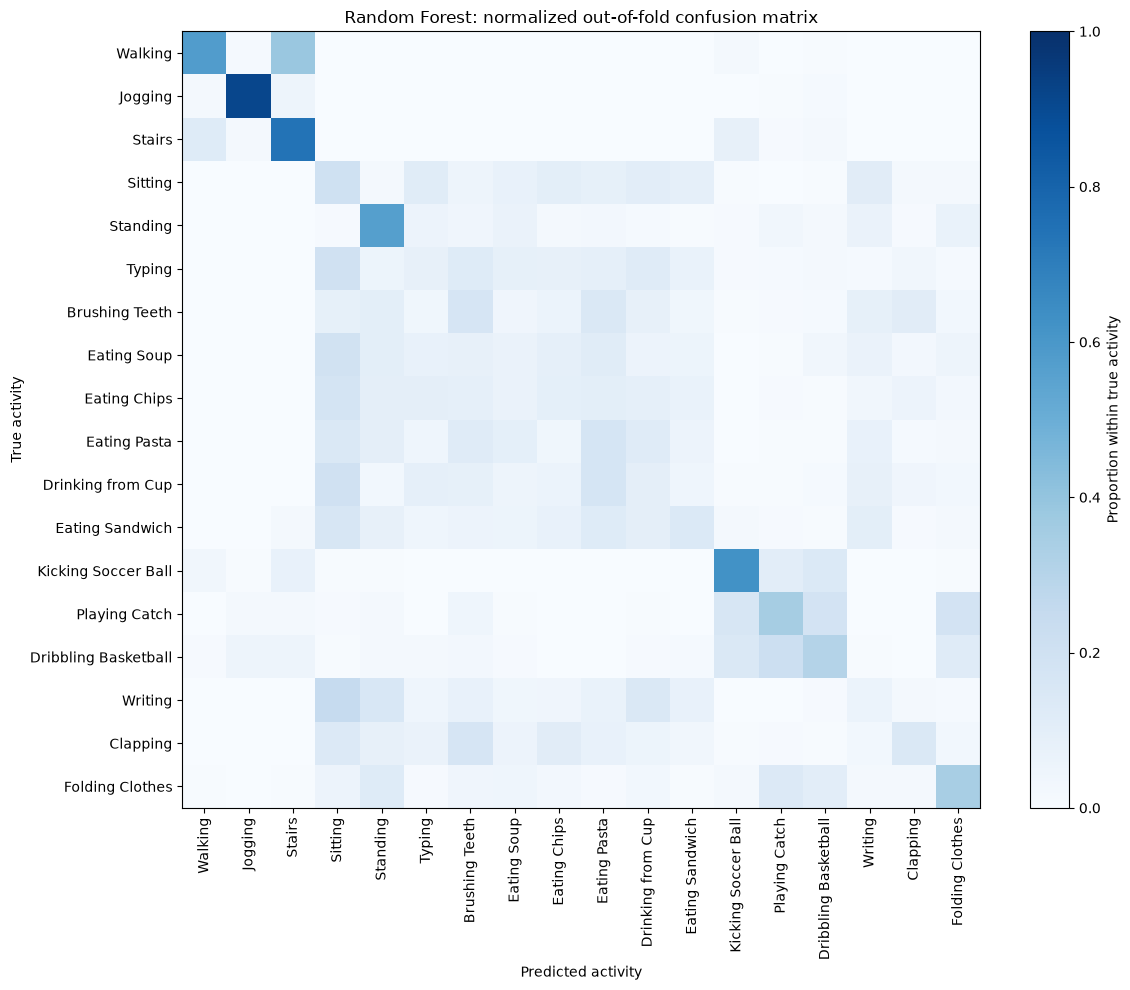

In [24]:
rf_confusion = rf_results["confusion_matrix"]

fig, ax = plt.subplots(figsize=(12, 10))

image = ax.imshow(
    rf_confusion,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(range(len(ACTIVITY_NAMES)))
ax.set_yticks(range(len(ACTIVITY_NAMES)))
ax.set_xticklabels(ACTIVITY_NAMES, rotation=90)
ax.set_yticklabels(ACTIVITY_NAMES)

ax.set(
    xlabel="Predicted activity",
    ylabel="True activity",
    title="Random Forest: normalized out-of-fold confusion matrix",
)

fig.colorbar(image, ax=ax, label="Proportion within true activity")
plt.tight_layout()
plt.show()

### 4.7 Random Forest findings

The phone-accelerometer Random Forest substantially exceeds the majority-class
baseline. Across the five subject folds, it achieves mean accuracy of 0.311,
mean balanced accuracy of 0.313, and mean macro-F1 of 0.302.

Performance is strongest for locomotion and other large-motion activities.
Jogging reaches an F1 score of 0.903, followed by Walking, Stairs, and Kicking
Soccer Ball. These activities produce comparatively distinctive motion
intensity and variability patterns.

Performance is much weaker for Writing, Eating Soup, Typing, Drinking from Cup,
and Eating Chips. These activities have overlapping phone-acceleration
summaries and often depend more strongly on hand motion that may be better
captured by the watch.

The confusion matrix shows additional overlap between Walking and Stairs and
among Kicking Soccer Ball, Playing Catch, and Dribbling Basketball. Static,
eating, and other fine-motor activities are distributed across several
predicted classes rather than forming clearly separated groups.

Performance also varies materially across held-out subjects. Subject-level
macro-F1 ranges from approximately 0.122 to 0.410, confirming that aggregate
window accuracy alone would hide important differences in generalization.

This is an untuned, phone-accelerometer-only baseline. The result should not be
interpreted as the final achievable performance, and the predefined test
subjects remain untouched.

## 5. Single-stream Random Forest diagnostic

To compare the information provided by each sensor stream, the same statistical
feature extraction and Random Forest evaluation are applied separately to:

- phone accelerometer;
- phone gyroscope;
- watch accelerometer;
- watch gyroscope.

These are four independent single-stream models, not a multimodal fusion model.
Each model uses the same subject folds, quality criteria, 28 statistical
features, Random Forest configuration, and evaluation metrics.

The predefined test subjects remain untouched.

### 5.1 Construct the four feature tables

In [25]:
STREAM_CONFIGS = {
    "phone_accel": {
        "device": "phone",
        "sensor": "accel",
        "label": "Phone accelerometer",
    },
    "phone_gyro": {
        "device": "phone",
        "sensor": "gyro",
        "label": "Phone gyroscope",
    },
    "watch_accel": {
        "device": "watch",
        "sensor": "accel",
        "label": "Watch accelerometer",
    },
    "watch_gyro": {
        "device": "watch",
        "sensor": "gyro",
        "label": "Watch gyroscope",
    },
}

# Reuse the already validated phone-accelerometer feature table.
stream_feature_tables = {
    "phone_accel": train_phone_features.copy()
}

support_records = []

for stream_name, config in STREAM_CONFIGS.items():
    stream_mask = (
        (train["device"] == config["device"])
        & (train["sensor"] == config["sensor"])
    )

    windows_before = train.loc[
        stream_mask, "window_id"
    ].nunique()

    valid_stream_mask = (
        stream_mask
        & train["window_id"].isin(quality_pass_window_ids)
    )

    windows_after = train.loc[
        valid_stream_mask, "window_id"
    ].nunique()

    if stream_name != "phone_accel":
        stream_samples = train.loc[
            valid_stream_mask,
            [
                "window_id",
                "window_idx",
                "user_id",
                "activity",
                "x",
                "y",
                "z",
            ],
        ].copy()

        stream_features = extract_statistical_features(
            stream_samples
        )

        stream_features["activity_name"] = (
            stream_features["activity_code"].map(ACTIVITY_MAP)
        )
        stream_features["fold"] = (
            stream_features["user_id"].map(FOLD_BY_SUBJECT)
        )

        stream_feature_tables[stream_name] = stream_features

        del stream_samples

    feature_table = stream_feature_tables[stream_name]

    assert feature_table["window_id"].is_unique
    assert feature_table["fold"].notna().all()
    assert feature_table[FEATURE_COLUMNS].notna().all().all()
    assert np.isfinite(
        feature_table[FEATURE_COLUMNS].to_numpy()
    ).all()

    support_records.append({
        "stream": stream_name,
        "stream_label": config["label"],
        "subjects": feature_table["user_id"].nunique(),
        "windows_before_quality": windows_before,
        "windows_after_quality": windows_after,
        "windows_removed": windows_before - windows_after,
        "feature_rows": len(feature_table),
    })

single_stream_support = pd.DataFrame(support_records)

display(single_stream_support)

,stream,stream_label,subjects,windows_before_quality,windows_after_quality,windows_removed,feature_rows
0,phone_accel,Phone accelerometer,41,25811,25811,0,25811
1,phone_gyro,Phone gyroscope,41,25622,25622,0,25622
2,watch_accel,Watch accelerometer,41,25708,25705,3,25705
3,watch_gyro,Watch gyroscope,41,25588,25585,3,25585


Check activity support

In [26]:
stream_activity_support = pd.concat(
    [
        (
            feature_table
            .groupby(
                ["activity_code", "activity_name"],
                observed=True,
            )
            .agg(
                windows=("window_id", "size"),
                subjects=("user_id", "nunique"),
            )
            .reset_index()
            .assign(stream=stream_name)
        )
        for stream_name, feature_table
        in stream_feature_tables.items()
    ],
    ignore_index=True,
)

display(
    stream_activity_support[
        [
            "stream",
            "activity_code",
            "activity_name",
            "windows",
            "subjects",
        ]
    ]
)

,stream,activity_code,activity_name,windows,subjects
0,phone_accel,A,Walking,1444,41
1,phone_accel,B,Jogging,1373,39
2,phone_accel,C,Stairs,1409,40
3,phone_accel,D,Sitting,1445,41
4,phone_accel,E,Standing,1447,41
...,...,...,...,...,...
67,watch_gyro,O,Playing Catch,1400,40
68,watch_gyro,P,Dribbling Basketball,1435,41
69,watch_gyro,Q,Writing,1435,41
70,watch_gyro,R,Clapping,1435,41


### 5.2 Evaluate the remaining streams

In [27]:
majority_predictions_by_stream = {
    "phone_accel": majority_predictions
}
majority_results_by_stream = {
    "phone_accel": majority_results
}

rf_predictions_by_stream = {
    "phone_accel": rf_predictions
}
rf_results_by_stream = {
    "phone_accel": rf_results
}

run_logs_by_stream = {
    "phone_accel": {
        "majority": majority_run_log,
        "random_forest": rf_run_log,
    }
}

Train the other three streams:

In [28]:
for stream_name, feature_table in stream_feature_tables.items():
    if stream_name == "phone_accel":
        continue

    print(f"\nEvaluating {STREAM_CONFIGS[stream_name]['label']}")

    stream_majority_predictions, stream_majority_log = (
        generate_oof_predictions(
            majority_model,
            feature_table,
            FEATURE_COLUMNS,
            model_name=f"{stream_name}_majority",
        )
    )

    stream_rf_predictions, stream_rf_log = (
        generate_oof_predictions(
            random_forest_model,
            feature_table,
            FEATURE_COLUMNS,
            model_name=f"{stream_name}_random_forest",
        )
    )

    majority_predictions_by_stream[stream_name] = (
        stream_majority_predictions
    )
    majority_results_by_stream[stream_name] = (
        summarize_oof_predictions(
            stream_majority_predictions
        )
    )

    rf_predictions_by_stream[stream_name] = (
        stream_rf_predictions
    )
    rf_results_by_stream[stream_name] = (
        summarize_oof_predictions(
            stream_rf_predictions
        )
    )

    run_logs_by_stream[stream_name] = {
        "majority": stream_majority_log,
        "random_forest": stream_rf_log,
    }


Evaluating Phone gyroscope
phone_gyro_majority — fold 1: 5,670 predictions in 0.00 seconds
phone_gyro_majority — fold 2: 5,041 predictions in 0.00 seconds
phone_gyro_majority — fold 3: 4,935 predictions in 0.00 seconds
phone_gyro_majority — fold 4: 5,040 predictions in 0.00 seconds
phone_gyro_majority — fold 5: 4,936 predictions in 0.00 seconds
phone_gyro_random_forest — fold 1: 5,670 predictions in 1.57 seconds
phone_gyro_random_forest — fold 2: 5,041 predictions in 1.68 seconds
phone_gyro_random_forest — fold 3: 4,935 predictions in 1.73 seconds
phone_gyro_random_forest — fold 4: 5,040 predictions in 1.60 seconds
phone_gyro_random_forest — fold 5: 4,936 predictions in 1.62 seconds

Evaluating Watch accelerometer
watch_accel_majority — fold 1: 5,671 predictions in 0.00 seconds
watch_accel_majority — fold 2: 5,010 predictions in 0.00 seconds
watch_accel_majority — fold 3: 4,970 predictions in 0.00 seconds
watch_accel_majority — fold 4: 5,048 predictions in 0.00 seconds
watch_accel_maj

### 5.3 Compare aggregate performance

In [29]:
diagnostic_rows = []

for stream_name, config in STREAM_CONFIGS.items():
    majority_summary = (
        majority_results_by_stream[stream_name]["fold_summary"]
    )
    rf_summary = (
        rf_results_by_stream[stream_name]["fold_summary"]
    )

    diagnostic_rows.append({
        "stream": config["label"],
        "windows": len(stream_feature_tables[stream_name]),
        "majority_macro_f1": majority_summary.loc[
            "macro_f1", "mean"
        ],
        "rf_accuracy_mean": rf_summary.loc[
            "accuracy", "mean"
        ],
        "rf_accuracy_std": rf_summary.loc[
            "accuracy", "std"
        ],
        "rf_balanced_accuracy_mean": rf_summary.loc[
            "balanced_accuracy", "mean"
        ],
        "rf_balanced_accuracy_std": rf_summary.loc[
            "balanced_accuracy", "std"
        ],
        "rf_macro_f1_mean": rf_summary.loc[
            "macro_f1", "mean"
        ],
        "rf_macro_f1_std": rf_summary.loc[
            "macro_f1", "std"
        ],
    })

single_stream_comparison = (
    pd.DataFrame(diagnostic_rows)
    .sort_values("rf_macro_f1_mean", ascending=False)
    .reset_index(drop=True)
)

display(single_stream_comparison)

,stream,windows,majority_macro_f1,rf_accuracy_mean,rf_accuracy_std,rf_balanced_accuracy_mean,rf_balanced_accuracy_std,rf_macro_f1_mean,rf_macro_f1_std
0,Watch accelerometer,25705,0.005888,0.658079,0.049412,0.658838,0.049582,0.656388,0.047386
1,Watch gyroscope,25585,0.005902,0.533514,0.043997,0.533909,0.043933,0.528840,0.041448
2,Phone accelerometer,25811,0.005888,0.311357,0.031070,0.312647,0.030013,0.301687,0.029573
3,Phone gyroscope,25622,0.005895,0.278991,0.014798,0.279827,0.013463,0.267530,0.018035


### 5.4 Compare performance by activity

In [30]:
per_activity_by_stream = pd.concat(
    [
        results["per_activity"].assign(
            stream=STREAM_CONFIGS[stream_name]["label"]
        )
        for stream_name, results
        in rf_results_by_stream.items()
    ],
    ignore_index=True,
)

activity_f1_table = (
    per_activity_by_stream
    .pivot(
        index="activity_name",
        columns="stream",
        values="f1",
    )
    .reindex(
        index=ACTIVITY_NAMES,
        columns=[
            config["label"]
            for config in STREAM_CONFIGS.values()
        ],
    )
)

display(activity_f1_table.round(3))

stream,Phone accelerometer,Phone gyroscope,Watch accelerometer,Watch gyroscope
activity_name,,,,
Walking,0.651,0.415,0.665,0.608
Jogging,0.903,0.571,0.945,0.774
Stairs,0.628,0.493,0.632,0.440
Sitting,0.143,0.193,0.571,0.528
Standing,0.446,0.330,0.666,0.422
Typing,0.087,0.101,0.702,0.566
Brushing Teeth,0.154,0.259,0.807,0.566
Eating Soup,0.074,0.137,0.560,0.388
Eating Chips,0.103,0.122,0.468,0.388


Plot the activity comparison:

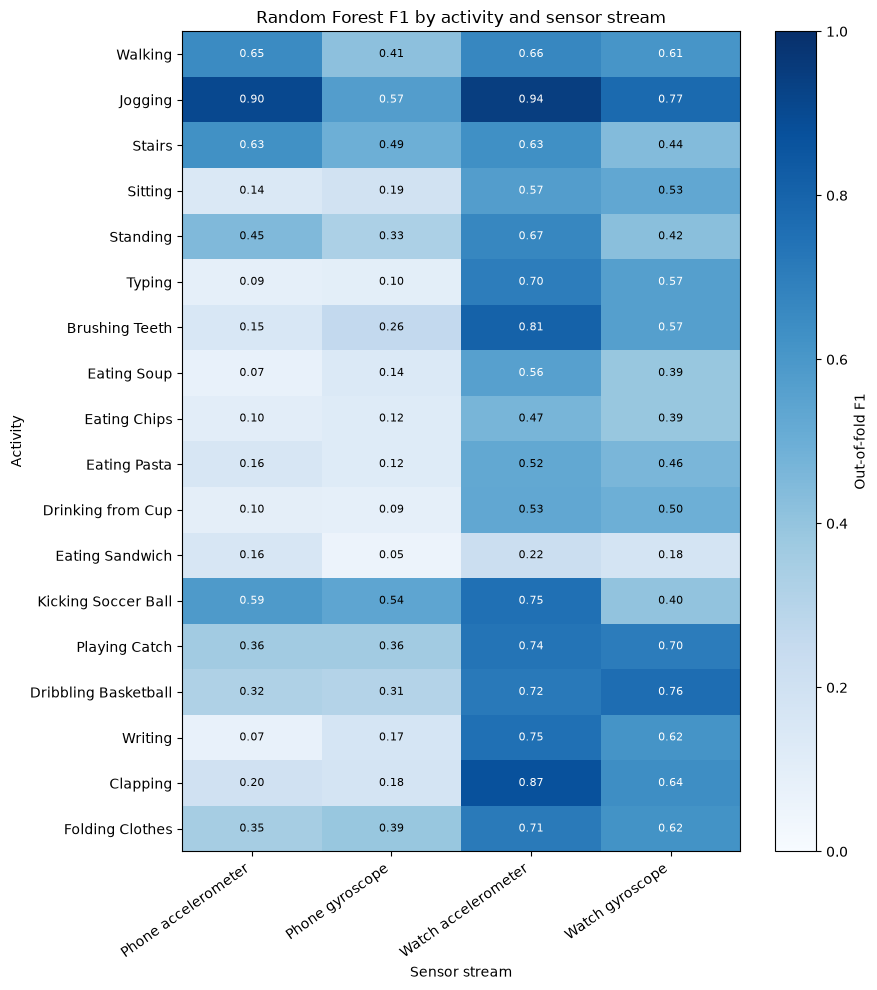

In [31]:
fig, ax = plt.subplots(figsize=(9, 10))

image = ax.imshow(
    activity_f1_table.to_numpy(),
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(range(activity_f1_table.shape[1]))
ax.set_yticks(range(activity_f1_table.shape[0]))

ax.set_xticklabels(
    activity_f1_table.columns,
    rotation=35,
    ha="right",
)
ax.set_yticklabels(activity_f1_table.index)

for row in range(activity_f1_table.shape[0]):
    for column in range(activity_f1_table.shape[1]):
        value = activity_f1_table.iloc[row, column]

        ax.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if value >= 0.55 else "black",
            fontsize=8,
        )

ax.set(
    xlabel="Sensor stream",
    ylabel="Activity",
    title="Random Forest F1 by activity and sensor stream",
)

fig.colorbar(image, ax=ax, label="Out-of-fold F1")
plt.tight_layout()
plt.show()

### 5.5 Fold and subject stability

Aggregate performance may conceal whether a sensor performs inconsistently
across validation folds or individual subjects. The following comparison uses
the same predefined subject folds for all four streams.

In [32]:
fold_metrics_by_stream = pd.concat(
    [
        results["fold_metrics"].assign(
            stream=STREAM_CONFIGS[stream_name]["label"]
        )
        for stream_name, results
        in rf_results_by_stream.items()
    ],
    ignore_index=True,
)

fold_macro_f1_table = (
    fold_metrics_by_stream
    .pivot(
        index="fold",
        columns="stream",
        values="macro_f1",
    )
    .reindex(
        columns=[
            config["label"]
            for config in STREAM_CONFIGS.values()
        ]
    )
)

display(fold_macro_f1_table.round(3))

fold_gain_over_phone_accel = (
    fold_macro_f1_table
    .subtract(
        fold_macro_f1_table["Phone accelerometer"],
        axis=0,
    )
    .drop(columns="Phone accelerometer")
)

print("Macro-F1 difference relative to phone accelerometer:")
display(fold_gain_over_phone_accel.round(3))

stream,Phone accelerometer,Phone gyroscope,Watch accelerometer,Watch gyroscope
fold,,,,
1,0.293,0.286,0.711,0.581
2,0.333,0.264,0.606,0.488
3,0.329,0.286,0.697,0.552
4,0.292,0.249,0.614,0.486
5,0.262,0.252,0.654,0.537


Macro-F1 difference relative to phone accelerometer:


stream,Phone gyroscope,Watch accelerometer,Watch gyroscope
fold,,,
1,-0.007,0.418,0.288
2,-0.069,0.273,0.155
3,-0.042,0.368,0.224
4,-0.043,0.322,0.194
5,-0.009,0.393,0.275


In [33]:
per_subject_by_stream = pd.concat(
    [
        results["per_subject"].assign(
            stream=STREAM_CONFIGS[stream_name]["label"]
        )
        for stream_name, results
        in rf_results_by_stream.items()
    ],
    ignore_index=True,
)

subject_stream_summary = (
    per_subject_by_stream
    .groupby("stream")["macro_f1"]
    .agg(["mean", "std", "min", "median", "max"])
    .reindex(
        [
            config["label"]
            for config in STREAM_CONFIGS.values()
        ]
    )
)

display(subject_stream_summary)

,mean,std,min,median,max
stream,,,,,
Phone accelerometer,0.276268,0.074592,0.121773,0.284056,0.409532
Phone gyroscope,0.253782,0.077366,0.107034,0.242322,0.420031
Watch accelerometer,0.638205,0.146245,0.133761,0.646738,0.826524
Watch gyroscope,0.512019,0.143091,0.072537,0.520599,0.727594


### 5.6 Single-stream diagnostic findings

The four single-stream Random Forest models show substantial differences in
activity-recognition performance.

Watch accelerometer is the strongest individual stream, achieving mean
subject-fold macro-F1 of 0.656. Watch gyroscope ranks second at 0.529, followed
by phone accelerometer at 0.302 and phone gyroscope at 0.268.

The advantage of the watch is consistent across all five validation folds.
Watch accelerometer improves macro-F1 over phone accelerometer by between 0.273
and 0.418 in every fold, while watch gyroscope improves it by between 0.155 and
0.288. Phone gyroscope does not outperform phone accelerometer in any fold.

Activity-level results strongly support the EDA findings. Watch accelerometer is
the best single stream for 17 of the 18 activities, producing particularly
large improvements for Typing, Brushing Teeth, Writing, Clapping, and the eating
and drinking activities. Watch gyroscope is strongest only for Dribbling
Basketball.

Eating Sandwich remains difficult for every individual stream, with a maximum
F1 of only 0.222. This suggests that the current whole-window statistical
features do not adequately separate this activity.

Although watch accelerometer performs best on average, its performance varies
substantially across subjects. Subject-level macro-F1 ranges from approximately
0.134 to 0.827, compared with 0.122 to 0.410 for phone accelerometer. The watch
therefore provides much stronger activity information but does not eliminate
the subject-generalization problem.

These results establish watch accelerometer as the strongest single-stream
classical baseline. They also motivate testing within-watch accelerometer and
gyroscope fusion, because gyroscope information may complement accelerometer
motion for particular activities or subjects. The current diagnostic does not
yet establish that fusion will improve performance.

All comparisons use development subjects only. The predefined test subjects
remain untouched.

## 6. Watch accelerometer–gyroscope feature fusion

This experiment tests whether the watch gyroscope adds useful information to
the stronger watch-accelerometer representation.

Corresponding accelerometer and gyroscope windows will be matched by subject,
activity, and ordinal window position. Their 28 statistical feature sets will
then be concatenated, producing 56 predictors per paired window.

For a fair comparison, all three models will be retrained on exactly the same
paired-window population:

1. watch accelerometer features only;
2. watch gyroscope features only;
3. concatenated watch accelerometer and gyroscope features.

The subject folds, Random Forest configuration, quality rules, and evaluation
metrics remain unchanged. Therefore, any difference between these models
reflects the available features rather than different window support.

The reserved test subjects remain untouched.

### 6.1 Pair corresponding watch windows

Window identifiers were created separately for each stream. We extract their
ordinal window position and match accelerometer and gyroscope windows using
subject, activity, and position.

First, we inspect how many windows occur in both streams and whether any
matching key is duplicated.

In [34]:
PAIR_KEYS = [
    "user_id",
    "activity_code",
    "window_position",
]


def add_window_position(feature_table):
    result = feature_table.copy()

    extracted_position = (
        result["window_id"]
        .astype("string")
        .str.extract(r"_(\d+)$", expand=False)
    )

    if extracted_position.isna().any():
        raise ValueError(
            "At least one window ID has no trailing window position."
        )

    result["window_position"] = (
        extracted_position.astype("int32")
    )

    return result


watch_accel_features = add_window_position(
    stream_feature_tables["watch_accel"]
)
watch_gyro_features = add_window_position(
    stream_feature_tables["watch_gyro"]
)

assert not watch_accel_features.duplicated(PAIR_KEYS).any()
assert not watch_gyro_features.duplicated(PAIR_KEYS).any()

watch_pair_membership = (
    watch_accel_features[
        PAIR_KEYS + ["window_id"]
    ]
    .rename(columns={"window_id": "accel_window_id"})
    .merge(
        watch_gyro_features[
            PAIR_KEYS + ["window_id"]
        ].rename(columns={"window_id": "gyro_window_id"}),
        on=PAIR_KEYS,
        how="outer",
        validate="one_to_one",
        indicator="pair_status",
    )
)

pair_status_counts = (
    watch_pair_membership["pair_status"]
    .value_counts(sort=False)
    .reindex(
        ["both", "left_only", "right_only"],
        fill_value=0,
    )
    .rename(
        index={
            "both": "Paired",
            "left_only": "Accelerometer only",
            "right_only": "Gyroscope only",
        }
    )
    .to_frame("windows")
)

pair_support_by_activity = (
    pd.crosstab(
        watch_pair_membership["activity_code"],
        watch_pair_membership["pair_status"],
    )
    .reindex(
        index=ACTIVITY_CODES,
        columns=["both", "left_only", "right_only"],
        fill_value=0,
    )
    .rename(index=ACTIVITY_MAP)
    .rename(
        columns={
            "both": "paired",
            "left_only": "accel_only",
            "right_only": "gyro_only",
        }
    )
)

display(pair_status_counts)
display(pair_support_by_activity)

print(
    "Subjects represented among paired windows:",
    watch_pair_membership.loc[
        watch_pair_membership["pair_status"] == "both",
        "user_id",
    ].nunique(),
)

,windows
pair_status,
Paired,25585
Accelerometer only,120
Gyroscope only,0


pair_status,paired,accel_only,gyro_only
activity_code,,,
Walking,1435,1,0
Jogging,1400,1,0
Stairs,1365,36,0
Sitting,1435,3,0
Standing,1435,1,0
Typing,1400,1,0
Brushing Teeth,1435,0,0
Eating Soup,1400,36,0
Eating Chips,1435,1,0


Subjects represented among paired windows: 41


### 6.2 Validate temporal alignment

Equal ordinal positions do not by themselves prove that two windows cover the
same time interval, because each sensor stream was windowed relative to its own
first timestamp.

We therefore compare the start and end timestamps of every proposed pair. A
positive offset means that the gyroscope window begins or ends later than the
accelerometer window. The overlap measures the duration jointly covered by
both streams.

In [35]:
TIMING_COLUMNS = [
    "window_id",
    "start_timestamp",
    "end_timestamp",
    "observed_span_s",
    "max_gap_s",
]


def attach_window_timing(feature_table, prefix):
    return (
        feature_table[
            PAIR_KEYS + ["window_id"]
        ]
        .merge(
            train_window_quality[TIMING_COLUMNS],
            on="window_id",
            how="left",
            validate="one_to_one",
        )
        .rename(
            columns={
                "window_id": f"{prefix}_window_id",
                "start_timestamp": f"{prefix}_start_timestamp",
                "end_timestamp": f"{prefix}_end_timestamp",
                "observed_span_s": f"{prefix}_observed_span_s",
                "max_gap_s": f"{prefix}_max_gap_s",
            }
        )
    )


watch_accel_timing = attach_window_timing(
    watch_accel_features,
    "accel",
)
watch_gyro_timing = attach_window_timing(
    watch_gyro_features,
    "gyro",
)

watch_pair_timing = watch_accel_timing.merge(
    watch_gyro_timing,
    on=PAIR_KEYS,
    how="inner",
    validate="one_to_one",
)

watch_pair_timing["start_offset_s"] = (
    watch_pair_timing["gyro_start_timestamp"]
    - watch_pair_timing["accel_start_timestamp"]
) / 1e9

watch_pair_timing["end_offset_s"] = (
    watch_pair_timing["gyro_end_timestamp"]
    - watch_pair_timing["accel_end_timestamp"]
) / 1e9

watch_pair_timing["overlap_s"] = (
    np.minimum(
        watch_pair_timing["accel_end_timestamp"],
        watch_pair_timing["gyro_end_timestamp"],
    )
    - np.maximum(
        watch_pair_timing["accel_start_timestamp"],
        watch_pair_timing["gyro_start_timestamp"],
    )
) / 1e9

watch_pair_timing["absolute_start_offset_s"] = (
    watch_pair_timing["start_offset_s"].abs()
)

print("Temporally compared pairs:", len(watch_pair_timing))

display(
    watch_pair_timing[
        [
            "start_offset_s",
            "end_offset_s",
            "overlap_s",
        ]
    ]
    .describe(
        percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
    )
    .T
)

print("Pairs with the largest start-time offsets:")

display(
    watch_pair_timing
    .nlargest(10, "absolute_start_offset_s")[
        [
            "user_id",
            "activity_code",
            "window_position",
            "accel_window_id",
            "gyro_window_id",
            "start_offset_s",
            "end_offset_s",
            "overlap_s",
        ]
    ]
)

Temporally compared pairs: 25585


,count,mean,std,min,1%,5%,50%,95%,99%,max
start_offset_s,25585.0,0.048963,0.031594,0.000000,0.000000,0.00000,0.049923,0.069524,0.164161,0.399487
end_offset_s,25585.0,0.048091,0.029443,0.000000,0.000000,0.00000,0.049924,0.060348,0.155843,0.399487
overlap_s,25585.0,4.903152,0.033180,4.534129,4.796512,4.88254,4.893215,4.946544,4.983302,4.997088


Pairs with the largest start-time offsets:


,user_id,activity_code,window_position,accel_window_id,gyro_window_id,start_offset_s,end_offset_s,overlap_s
1874,1602,S,19,1602_watch_accel_S_0019,1602_watch_gyro_S_0019,0.399487,0.349495,4.593700
1881,1602,S,26,1602_watch_accel_S_0026,1602_watch_gyro_S_0026,0.399476,0.349550,4.593825
15802,1630,C,17,1630_watch_accel_C_0017,1630_watch_gyro_C_0017,0.399436,0.399395,4.543050
1867,1602,S,12,1602_watch_accel_S_0012,1602_watch_gyro_S_0012,0.399432,0.349522,4.593433
15804,1630,C,19,1630_watch_accel_C_0019,1630_watch_gyro_C_0019,0.399429,0.399425,4.543549
15805,1630,C,20,1630_watch_accel_C_0020,1630_watch_gyro_C_0020,0.399424,0.349468,4.592907
15816,1630,C,31,1630_watch_accel_C_0031,1630_watch_gyro_C_0031,0.399421,0.399398,4.542977
15810,1630,C,25,1630_watch_accel_C_0025,1630_watch_gyro_C_0025,0.399419,0.399357,4.542960
15815,1630,C,30,1630_watch_accel_C_0030,1630_watch_gyro_C_0030,0.399411,0.399425,4.543312
15819,1630,C,34,1630_watch_accel_C_0034,1630_watch_gyro_C_0034,0.399410,0.349457,4.593049


#### Pairing and alignment findings

All 25,585 valid watch-gyroscope windows have a corresponding
watch-accelerometer window. An additional 120 accelerometer windows have no
gyroscope partner and are excluded from the controlled comparison. This removes
approximately 0.47% of the valid watch-accelerometer windows while retaining all
41 development subjects.

The paired streams are closely aligned. The median gyroscope start offset is
approximately 0.05 seconds, 99% of offsets are no greater than approximately
0.164 seconds, and the maximum is approximately 0.40 seconds. Every pair shares
at least 4.53 seconds of temporal coverage.

This alignment is adequate for fusing whole-window statistical features. No
additional temporal-alignment exclusions are required

### 6.3 Construct the paired feature table

The accelerometer and gyroscope features are renamed to preserve their sensor
identity and then joined one-to-one. The resulting table contains 28
accelerometer features and 28 gyroscope features for each paired window.

A new canonical window identifier represents the pair and is used only for
tracking out-of-fold predictions.

In [36]:
WATCH_ACCEL_FEATURE_COLUMNS = [
    f"accel_{column}" for column in FEATURE_COLUMNS
]
WATCH_GYRO_FEATURE_COLUMNS = [
    f"gyro_{column}" for column in FEATURE_COLUMNS
]
WATCH_FUSION_FEATURE_COLUMNS = (
    WATCH_ACCEL_FEATURE_COLUMNS
    + WATCH_GYRO_FEATURE_COLUMNS
)

accel_feature_rename = {
    "window_id": "accel_window_id",
    "activity_name": "accel_activity_name",
    "fold": "accel_fold",
    "n_samples": "accel_n_samples",
    **{
        column: f"accel_{column}"
        for column in FEATURE_COLUMNS
    },
}

gyro_feature_rename = {
    "window_id": "gyro_window_id",
    "activity_name": "gyro_activity_name",
    "fold": "gyro_fold",
    "n_samples": "gyro_n_samples",
    **{
        column: f"gyro_{column}"
        for column in FEATURE_COLUMNS
    },
}

accel_fusion_side = (
    watch_accel_features[
        PAIR_KEYS
        + [
            "window_id",
            "activity_name",
            "fold",
            "n_samples",
            *FEATURE_COLUMNS,
        ]
    ]
    .rename(columns=accel_feature_rename)
)

gyro_fusion_side = (
    watch_gyro_features[
        PAIR_KEYS
        + [
            "window_id",
            "activity_name",
            "fold",
            "n_samples",
            *FEATURE_COLUMNS,
        ]
    ]
    .rename(columns=gyro_feature_rename)
)

paired_watch_features = accel_fusion_side.merge(
    gyro_fusion_side,
    on=PAIR_KEYS,
    how="inner",
    validate="one_to_one",
)

assert paired_watch_features[
    "accel_activity_name"
].equals(
    paired_watch_features["gyro_activity_name"]
)

assert paired_watch_features[
    "accel_fold"
].equals(
    paired_watch_features["gyro_fold"]
)

paired_watch_features["activity_name"] = (
    paired_watch_features["accel_activity_name"]
)
paired_watch_features["fold"] = (
    paired_watch_features["accel_fold"].astype("int8")
)

paired_watch_features["window_id"] = (
    paired_watch_features["user_id"].astype(str)
    + "_watch_fused_"
    + paired_watch_features["activity_code"].astype(str)
    + "_"
    + paired_watch_features[
        "window_position"
    ].astype(str).str.zfill(4)
)

paired_watch_features = paired_watch_features.merge(
    watch_pair_timing[
        PAIR_KEYS
        + [
            "start_offset_s",
            "end_offset_s",
            "overlap_s",
        ]
    ],
    on=PAIR_KEYS,
    how="left",
    validate="one_to_one",
)

paired_watch_features = paired_watch_features.drop(
    columns=[
        "accel_activity_name",
        "gyro_activity_name",
        "accel_fold",
        "gyro_fold",
    ]
)

paired_fold_activity_support = (
    pd.crosstab(
        paired_watch_features["fold"],
        paired_watch_features["activity_name"],
    )
    .reindex(columns=ACTIVITY_NAMES, fill_value=0)
)

print("Paired feature rows:", len(paired_watch_features))
print(
    "Accelerometer features:",
    len(WATCH_ACCEL_FEATURE_COLUMNS),
)
print(
    "Gyroscope features:",
    len(WATCH_GYRO_FEATURE_COLUMNS),
)
print(
    "Fusion features:",
    len(WATCH_FUSION_FEATURE_COLUMNS),
)
print(
    "Subjects:",
    paired_watch_features["user_id"].nunique(),
)
print(
    "Duplicate paired-window IDs:",
    paired_watch_features["window_id"].duplicated().sum(),
)
print(
    "Missing feature values:",
    int(
        paired_watch_features[
            WATCH_FUSION_FEATURE_COLUMNS
        ].isna().sum().sum()
    ),
)

assert len(paired_watch_features) == len(watch_pair_timing)
assert paired_watch_features["window_id"].is_unique
assert paired_watch_features["fold"].notna().all()
assert (
    paired_watch_features["overlap_s"]
    >= MIN_OBSERVED_SPAN_S
).all()
assert paired_watch_features[
    WATCH_FUSION_FEATURE_COLUMNS
].notna().all().all()
assert np.isfinite(
    paired_watch_features[
        WATCH_FUSION_FEATURE_COLUMNS
    ].to_numpy()
).all()
assert (paired_fold_activity_support > 0).all().all()

display(paired_fold_activity_support)

Paired feature rows: 25585
Accelerometer features: 28
Gyroscope features: 28
Fusion features: 56
Subjects: 41
Duplicate paired-window IDs: 0
Missing feature values: 0


activity_name,Walking,Jogging,Stairs,Sitting,Standing,Typing,Brushing Teeth,Eating Soup,Eating Chips,Eating Pasta,Drinking from Cup,Eating Sandwich,Kicking Soccer Ball,Playing Catch,Dribbling Basketball,Writing,Clapping,Folding Clothes
fold,,,,,,,,,,,,,,,,,,
1,315,315,315,315,315,315,315,315,315,315,315,315,315,315,315,315,315,315
2,280,280,245,280,280,280,280,280,280,245,280,280,280,280,280,280,280,280
3,280,280,245,280,280,245,280,280,280,280,280,280,280,280,280,280,280,280
4,280,280,280,280,280,280,280,245,280,280,280,280,280,245,280,280,280,280
5,280,245,280,280,280,280,280,280,280,280,280,280,280,280,280,280,280,280


### 6.4 Controlled out-of-fold comparison

Three Random Forest models are now fitted on the identical paired-window
population. The only difference between them is whether they receive
accelerometer features, gyroscope features, or both feature sets.

Using the same windows and validation folds isolates the effect of adding
gyroscope information.

In [37]:
WATCH_FUSION_CONFIGS = {
    "watch_accel_paired": {
        "label": "Watch accelerometer (paired)",
        "features": WATCH_ACCEL_FEATURE_COLUMNS,
    },
    "watch_gyro_paired": {
        "label": "Watch gyroscope (paired)",
        "features": WATCH_GYRO_FEATURE_COLUMNS,
    },
    "watch_accel_gyro_fusion": {
        "label": "Watch accel + gyro fusion",
        "features": WATCH_FUSION_FEATURE_COLUMNS,
    },
}

watch_fusion_predictions = {}
watch_fusion_results = {}
watch_fusion_run_logs = {}

for model_name, config in WATCH_FUSION_CONFIGS.items():
    print(f"\nEvaluating {config['label']}")

    predictions, run_log = generate_oof_predictions(
        random_forest_model,
        paired_watch_features,
        config["features"],
        model_name=model_name,
    )

    watch_fusion_predictions[model_name] = predictions
    watch_fusion_results[model_name] = (
        summarize_oof_predictions(predictions)
    )
    watch_fusion_run_logs[model_name] = run_log


Evaluating Watch accelerometer (paired)
watch_accel_paired — fold 1: 5,670 predictions in 1.47 seconds
watch_accel_paired — fold 2: 4,970 predictions in 1.49 seconds
watch_accel_paired — fold 3: 4,970 predictions in 1.53 seconds
watch_accel_paired — fold 4: 4,970 predictions in 1.59 seconds
watch_accel_paired — fold 5: 5,005 predictions in 1.52 seconds

Evaluating Watch gyroscope (paired)
watch_gyro_paired — fold 1: 5,670 predictions in 1.52 seconds
watch_gyro_paired — fold 2: 4,970 predictions in 1.61 seconds
watch_gyro_paired — fold 3: 4,970 predictions in 1.67 seconds
watch_gyro_paired — fold 4: 4,970 predictions in 1.71 seconds
watch_gyro_paired — fold 5: 5,005 predictions in 1.59 seconds

Evaluating Watch accel + gyro fusion
watch_accel_gyro_fusion — fold 1: 5,670 predictions in 1.97 seconds
watch_accel_gyro_fusion — fold 2: 4,970 predictions in 2.06 seconds
watch_accel_gyro_fusion — fold 3: 4,970 predictions in 2.08 seconds
watch_accel_gyro_fusion — fold 4: 4,970 predictions in 

### 6.5 Compare fusion performance

Fusion should be judged primarily by its mean subject-fold macro-F1 and by
whether its improvement over accelerometer alone is consistent across folds,
activities, and held-out subjects.

In [38]:
watch_fusion_fold_table = (
    pd.concat(
        [
            results["fold_metrics"].assign(
                model=WATCH_FUSION_CONFIGS[
                    model_name
                ]["label"]
            )
            for model_name, results
            in watch_fusion_results.items()
        ],
        ignore_index=True,
    )
    .pivot(
        index="fold",
        columns="model",
        values="macro_f1",
    )
    .reindex(
        columns=[
            config["label"]
            for config in WATCH_FUSION_CONFIGS.values()
        ]
    )
)

watch_fusion_fold_table[
    "Fusion gain over accelerometer"
] = (
    watch_fusion_fold_table[
        "Watch accel + gyro fusion"
    ]
    - watch_fusion_fold_table[
        "Watch accelerometer (paired)"
    ]
)

display(watch_fusion_fold_table.round(4))

model,Watch accelerometer (paired),Watch gyroscope (paired),Watch accel + gyro fusion,Fusion gain over accelerometer
fold,,,,
1,0.7100,0.5814,0.7432,0.0332
2,0.6039,0.4884,0.6325,0.0286
3,0.6969,0.5521,0.7331,0.0363
4,0.6236,0.4856,0.6551,0.0315
5,0.6548,0.5366,0.6899,0.0350


In [39]:
watch_fusion_activity_table = (
    pd.concat(
        [
            results["per_activity"].assign(
                model=WATCH_FUSION_CONFIGS[
                    model_name
                ]["label"]
            )
            for model_name, results
            in watch_fusion_results.items()
        ],
        ignore_index=True,
    )
    .pivot(
        index="activity_name",
        columns="model",
        values="f1",
    )
    .reindex(
        index=ACTIVITY_NAMES,
        columns=[
            config["label"]
            for config in WATCH_FUSION_CONFIGS.values()
        ],
    )
)

watch_fusion_activity_table[
    "Fusion gain over accelerometer"
] = (
    watch_fusion_activity_table[
        "Watch accel + gyro fusion"
    ]
    - watch_fusion_activity_table[
        "Watch accelerometer (paired)"
    ]
)

display(watch_fusion_activity_table.round(3))

model,Watch accelerometer (paired),Watch gyroscope (paired),Watch accel + gyro fusion,Fusion gain over accelerometer
activity_name,,,,
Walking,0.668,0.608,0.719,0.051
Jogging,0.945,0.774,0.960,0.015
Stairs,0.632,0.440,0.676,0.045
Sitting,0.575,0.528,0.588,0.013
Standing,0.666,0.422,0.683,0.016
Typing,0.700,0.566,0.720,0.020
Brushing Teeth,0.804,0.566,0.819,0.015
Eating Soup,0.571,0.388,0.598,0.027
Eating Chips,0.469,0.388,0.507,0.038


In [40]:
watch_fusion_subject_table = (
    pd.concat(
        [
            results["per_subject"].assign(
                model=WATCH_FUSION_CONFIGS[
                    model_name
                ]["label"]
            )
            for model_name, results
            in watch_fusion_results.items()
        ],
        ignore_index=True,
    )
    .pivot(
        index="user_id",
        columns="model",
        values="macro_f1",
    )
    .reindex(
        columns=[
            config["label"]
            for config in WATCH_FUSION_CONFIGS.values()
        ]
    )
)

watch_fusion_subject_table[
    "Fusion gain over accelerometer"
] = (
    watch_fusion_subject_table[
        "Watch accel + gyro fusion"
    ]
    - watch_fusion_subject_table[
        "Watch accelerometer (paired)"
    ]
)

subject_fusion_gain = watch_fusion_subject_table[
    "Fusion gain over accelerometer"
]

display(watch_fusion_subject_table.round(3))

print(
    "Subjects improved by fusion:",
    int((subject_fusion_gain > 0).sum()),
    "of",
    len(subject_fusion_gain),
)
print(
    "Subjects worsened by fusion:",
    int((subject_fusion_gain < 0).sum()),
)
display(
    subject_fusion_gain
    .describe()
    .to_frame("fusion_gain")
)

model,Watch accelerometer (paired),Watch gyroscope (paired),Watch accel + gyro fusion,Fusion gain over accelerometer
user_id,,,,
1600,0.822,0.728,0.886,0.064
1601,0.697,0.459,0.694,-0.002
1602,0.744,0.596,0.769,0.024
1603,0.549,0.420,0.571,0.022
1604,0.703,0.511,0.703,-0.001
1605,0.755,0.492,0.779,0.024
1608,0.586,0.452,0.572,-0.014
1609,0.625,0.472,0.683,0.059
1610,0.811,0.684,0.837,0.027


Subjects improved by fusion: 33 of 41
Subjects worsened by fusion: 8


,fusion_gain
count,41.000000
mean,0.032019
std,0.027552
min,-0.014741
25%,0.016362
50%,0.033483
75%,0.044923
max,0.088900


In [41]:
fusion_comparison_rows = []

for model_name, config in WATCH_FUSION_CONFIGS.items():
    summary = watch_fusion_results[
        model_name
    ]["fold_summary"]

    fusion_comparison_rows.append({
        "model": config["label"],
        "features": len(config["features"]),
        "windows": len(paired_watch_features),
        "accuracy_mean": summary.loc["accuracy", "mean"],
        "accuracy_std": summary.loc["accuracy", "std"],
        "balanced_accuracy_mean": summary.loc[
            "balanced_accuracy", "mean"
        ],
        "balanced_accuracy_std": summary.loc[
            "balanced_accuracy", "std"
        ],
        "macro_f1_mean": summary.loc["macro_f1", "mean"],
        "macro_f1_std": summary.loc["macro_f1", "std"],
    })

watch_fusion_comparison = pd.DataFrame(
    fusion_comparison_rows
)

display(watch_fusion_comparison.round(4))

,model,features,windows,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
0,Watch accelerometer (paired),28,25585,0.6595,0.0476,0.6604,0.0476,0.6578,0.0456
1,Watch gyroscope (paired),28,25585,0.5335,0.0440,0.5339,0.0439,0.5288,0.0414
2,Watch accel + gyro fusion,56,25585,0.6920,0.0515,0.6929,0.0511,0.6907,0.0480


### 6.6 Detailed evaluation of the fused baseline

Because feature fusion outperforms both paired single-stream models, it becomes
the main classical baseline. We therefore inspect its complete per-activity
metrics, held-out-subject distribution, and normalized confusion matrix.

In [42]:
fused_rf_results = watch_fusion_results[
    "watch_accel_gyro_fusion"
]

print("Overall out-of-fold metrics:")
display(
    fused_rf_results["overall"].to_frame("value")
)

print("Per-activity performance:")
display(
    fused_rf_results["per_activity"]
    .sort_values("f1")
    .reset_index(drop=True)
)

print("Distribution across held-out subjects:")
display(
    fused_rf_results["per_subject"][
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ]
    .describe()
    .T
)

print("Lowest-performing held-out subjects:")
display(
    fused_rf_results["per_subject"]
    .nsmallest(10, "macro_f1")
)

Overall out-of-fold metrics:


,value
accuracy,0.693570
balanced_accuracy,0.693758
macro_f1,0.691807


Per-activity performance:


,activity_code,activity_name,precision,recall,f1,support
0,L,Eating Sandwich,0.291051,0.233449,0.259087,1435
1,I,Eating Chips,0.494048,0.520557,0.506956,1435
2,K,Drinking from Cup,0.545756,0.573519,0.559293,1435
3,J,Eating Pasta,0.539283,0.612857,0.573721,1400
4,D,Sitting,0.586685,0.589547,0.588113,1435
5,H,Eating Soup,0.630245,0.568571,0.597822,1400
6,C,Stairs,0.692780,0.660806,0.676415,1365
7,E,Standing,0.648276,0.720557,0.682508,1435
8,A,Walking,0.816092,0.643206,0.719408,1435
9,F,Typing,0.775124,0.672143,0.719969,1400


Distribution across held-out subjects:


,count,mean,std,min,25%,50%,75%,max
accuracy,41.0,0.690509,0.152844,0.148214,0.614286,0.725397,0.774603,0.890476
balanced_accuracy,41.0,0.690509,0.152844,0.148214,0.614286,0.725397,0.774603,0.890476
macro_f1,41.0,0.669893,0.158533,0.110874,0.582690,0.699352,0.768653,0.886005


Lowest-performing held-out subjects:


,user_id,n_windows,accuracy,balanced_accuracy,macro_f1
32,1637,560,0.148214,0.148214,0.110874
33,1638,560,0.173214,0.173214,0.163906
35,1644,630,0.544444,0.544444,0.515627
28,1633,630,0.550794,0.550794,0.529999
10,1612,630,0.587302,0.587302,0.547239
17,1620,630,0.598413,0.598413,0.567136
3,1603,630,0.612698,0.612698,0.570723
6,1608,630,0.604762,0.604762,0.572029
38,1648,630,0.598413,0.598413,0.577489
34,1642,560,0.600000,0.600000,0.580264


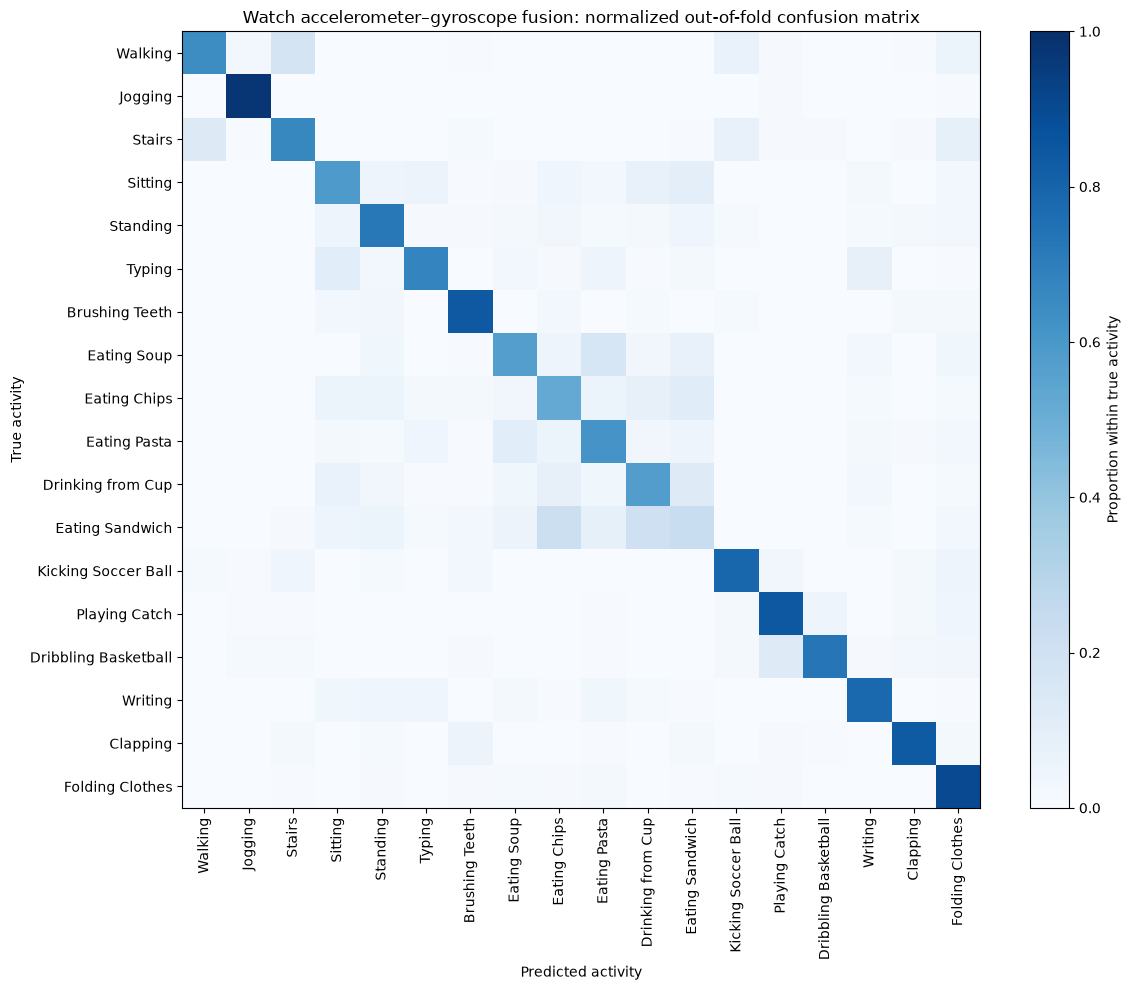

In [43]:
fused_rf_confusion = fused_rf_results[
    "confusion_matrix"
]

fig, ax = plt.subplots(figsize=(12, 10))

image = ax.imshow(
    fused_rf_confusion,
    cmap="Blues",
    vmin=0,
    vmax=1,
    aspect="auto",
)

ax.set_xticks(range(len(ACTIVITY_NAMES)))
ax.set_yticks(range(len(ACTIVITY_NAMES)))
ax.set_xticklabels(ACTIVITY_NAMES, rotation=90)
ax.set_yticklabels(ACTIVITY_NAMES)

ax.set(
    xlabel="Predicted activity",
    ylabel="True activity",
    title=(
        "Watch accelerometer–gyroscope fusion: "
        "normalized out-of-fold confusion matrix"
    ),
)

fig.colorbar(
    image,
    ax=ax,
    label="Proportion within true activity",
)

plt.tight_layout()
plt.show()

### 6.7 Feature-fusion findings

Combining watch accelerometer and gyroscope features produces the strongest
classical baseline evaluated in this notebook.

Across the five fixed subject-validation folds, fusion achieves mean accuracy
of 0.692 ± 0.052, mean balanced accuracy of 0.693 ± 0.051, and the primary
mean macro-F1 of 0.691 ± 0.048. The pooled out-of-fold macro-F1 is 0.692.

On the identical 25,585-window population, the paired accelerometer model
achieves mean macro-F1 of 0.658, while the paired gyroscope model achieves
0.529. Fusion therefore improves macro-F1 over accelerometer alone by
approximately 0.033. The gain is present in every validation fold and ranges
from 0.029 to 0.036, indicating that it is not driven by a single subject
split.

Fusion improves F1 for 17 of the 18 activities. The largest gains occur for
Dribbling Basketball, Playing Catch, Walking, Eating Pasta, and Stairs. This
supports the hypothesis that gyroscope measurements provide complementary
rotational-motion information. Clapping is the only activity that declines,
although its fused F1 remains high at 0.845.

Jogging is the best-recognized activity, with F1 of 0.960. Playing Catch,
Brushing Teeth, Dribbling Basketball, Clapping, and Writing also perform
strongly. Eating Sandwich remains the most difficult activity, with F1 of only
0.259. The confusion matrix shows that many remaining errors occur among the
eating and drinking activities, between Walking and Stairs, and between Playing
Catch and Dribbling Basketball. Folding Clothes has high recall but lower
precision, indicating that some other activities are incorrectly assigned to
this class.

Fusion improves subject-level macro-F1 for 33 of the 41 held-out development
subjects. The mean subject-level gain is 0.032, while the largest observed loss
is only 0.015. Nevertheless, subject performance remains highly variable:
macro-F1 ranges from 0.111 to 0.886. Subjects 1637 and 1638 perform particularly
poorly, showing that substantial subject-specific generalization difficulty
remains despite the stronger sensor representation.

These results establish watch accelerometer–gyroscope statistical feature
fusion as the main classical Random Forest baseline. They justify retaining
both watch sensors in subsequent preprocessing and model development, while
also providing a clear benchmark against which more expressive temporal models
can be compared.

All feature choices and comparisons were made using development subjects only.
The predefined test subjects remain untouched and must not be evaluated until
the final preprocessing and model-selection decisions have been fixed.